# 05 · BPR, рекомендации по метаданным и гибрид

После ALS проверяю ещё два источника рекомендаций. BPR напрямую учится ставить просмотренный объект выше случайного объекта из каталога. Content-Based использует жанры, страны, режиссёров и тип контента вместо совместных просмотров.

Для BPR сравниваю 32 и 64 фактора. Для Content кодирую значения метаданных через TF-IDF и рассчитываю косинусные соседства только для объектов, известных к началу периода.

Затем объединяю списки Popularity, ItemKNN, ALS и Content через Reciprocal Rank Fusion: `sum(weight / (60 + rank))`. Здесь удобнее складывать позиции, потому что исходные scores моделей имеют разный масштаб. Проверяю два набора весов на Validation.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Данные и параметры

In [2]:
metrics = pd.read_csv(REPORTS / "metrics.csv")
grid = pd.read_csv(REPORTS / "validation_grid.csv")
selected = json.loads((REPORTS / "selected_params.json").read_text())
display(
    grid.loc[
        grid.model.isin(["BPR", "Content", "Hybrid"]),
        ["model", "params", "MAP@10", "Recall@10", "NDCG@10", "Coverage"],
    ]
)

,model,params,MAP@10,Recall@10,NDCG@10,Coverage
6,BPR,"{""factors"": 32, ""regularization"": 0.01, ""itera...",0.096810,0.188053,0.126220,0.502101
7,BPR,"{""factors"": 64, ""regularization"": 0.01, ""itera...",0.096751,0.188352,0.126391,0.513105
8,Content,"{""neighbors"": 50}",0.077675,0.150270,0.100310,0.514022
9,Content,"{""neighbors"": 100}",0.077661,0.150320,0.100308,0.510812
10,Hybrid,"{""Popularity"": 0.5, ""ItemKNN"": 1, ""ALS"": 1, ""C...",0.117083,0.247345,0.159188,0.234278
11,Hybrid,"{""Popularity"": 0.5, ""ItemKNN"": 1, ""ALS"": 1, ""C...",0.114741,0.244330,0.156480,0.286085


## Результаты

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
model,,,,,,
Popularity,0.1215,0.2366,0.1598,0.3127,0.0027,106819
ALS,0.1012,0.2158,0.1386,0.2949,0.0621,106819
BPR,0.0851,0.1704,0.1127,0.2240,0.5085,106819
Content,0.0671,0.1343,0.0880,0.1680,0.5158,106819
Hybrid,0.1056,0.2304,0.1460,0.3154,0.2385,106819


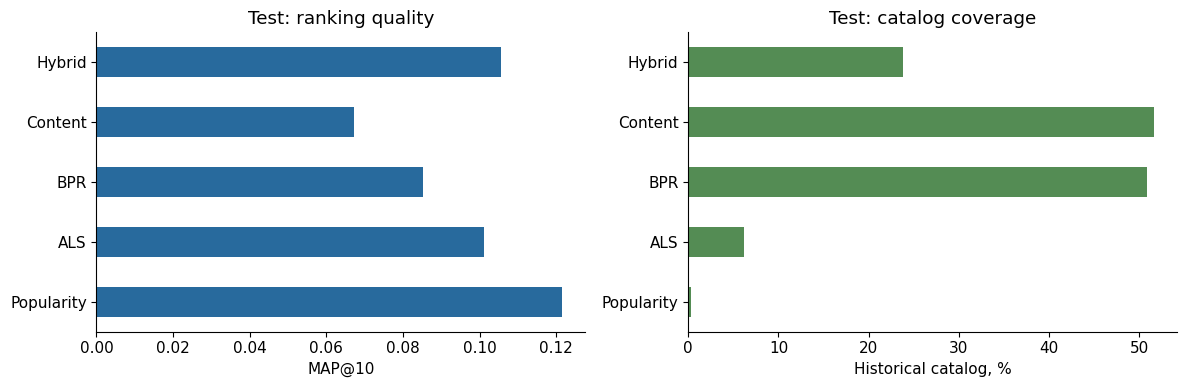

In [3]:
comparison = metrics.query(
    "split == 'test' and model in ['Popularity', 'ALS', 'BPR', 'Content', 'Hybrid']"
).set_index("model")
display(comparison.drop(columns=["split", "seconds"]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["MAP@10"].plot.barh(ax=axes[0], color="#286a9d")
comparison["Coverage"].mul(100).plot.barh(ax=axes[1], color="#548c54")
axes[0].set(title="Test: ranking quality", xlabel="MAP@10", ylabel="")
axes[1].set(title="Test: catalog coverage", xlabel="Historical catalog, %", ylabel="")
plt.tight_layout()
plt.show()

## Метаданные и ограничения

In [4]:
items = pd.read_csv(DATA_DIR / "items.csv")
fields = ["genres", "countries", "directors", "content_type"]
display(items[fields].isna().mean().mul(100).to_frame("missing_pct").round(2))

,missing_pct
genres,0.00
countries,0.23
directors,9.45
content_type,0.00


## Выводы

BPR получил MAP@10 **0,0851**, Content — **0,0671**. Обе модели уступили Popularity, хотя их выдача охватывает около половины исторического каталога.

У Content особенно слабые результаты для пользователей с историей. Жанры и страны дают слишком общее описание предпочтений; заметная часть общей метрики приходится на популярную выдачу новым пользователям.

Смешивание рангов тоже не улучшило baseline: MAP@10 гибрида — **0,1056**. Дальше попробую обучить ранкер на признаках пользователя и кандидата, чтобы вклад каждого источника мог зависеть от конкретной пары.